In [1]:
# Import Required Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import time
import json
import os
import math
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import layers, models
import random

In [2]:
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

***Dataset Loading***

In [3]:
# Dataset Loading

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
data_path = "PJM_Load_hourly.csv"
df = pd.read_csv(data_path)

# Display basic information
print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())

# Convert Datetime column to datetime type
df['Datetime'] = pd.to_datetime(df['Datetime'])

# Sort by time
df = df.sort_values('Datetime')

# Set Datetime as index
df.set_index('Datetime', inplace=True)

# Rename target column for convenience
df.rename(columns={'PJM_Load_MW': 'load'}, inplace=True)

# Check for missing values
print("\nMissing values:\n", df.isna().sum())

# Display first few rows
df.head()


Dataset shape: (32896, 2)

Column names: ['Datetime', 'PJM_Load_MW']

Missing values:
 load    0
dtype: int64


,load
Datetime,
1998-04-01 01:00:00,22259.0
1998-04-01 02:00:00,21244.0
1998-04-01 03:00:00,20651.0
1998-04-01 04:00:00,20421.0
1998-04-01 05:00:00,20713.0


In [4]:
dataset_name = "PJM Hourly Electricity Load (Energy Consumption)"
dataset_source = "Kaggle - PJM Hourly Energy Consumption Dataset"
n_samples = df.shape[0]  
n_features = 1  
sequence_length = 24  
prediction_horizon = 1  
problem_type = "time_series_forecasting"

In [5]:
# Primary metric selection
primary_metric = "MAE"
metric_justification = """
MAE is chosen as the primary metric because it provides a clear and interpretable
measure of average prediction error in the same units as the target variable
(megawatts of electricity consumption). It is robust to outliers compared to RMSE
and avoids instability issues associated with MAPE when values are small.
"""

In [6]:
print("\n" + "="*70)
print("DATASET INFORMATION")
print("="*70)
print(f"Dataset: {dataset_name}")
print(f"Source: {dataset_source}")
print(f"Total Samples: {n_samples}")
print(f"Number of Features: {n_features}")
print(f"Sequence Length: {sequence_length}")
print(f"Prediction Horizon: {prediction_horizon}")
print(f"Primary Metric: {primary_metric}")
print(f"Metric Justification: {metric_justification}")
print("="*70)


DATASET INFORMATION
Dataset: PJM Hourly Electricity Load (Energy Consumption)
Source: Kaggle - PJM Hourly Energy Consumption Dataset
Total Samples: 32896
Number of Features: 1
Sequence Length: 24
Prediction Horizon: 1
Primary Metric: MAE
Metric Justification: 
MAE is chosen as the primary metric because it provides a clear and interpretable
measure of average prediction error in the same units as the target variable
(megawatts of electricity consumption). It is robust to outliers compared to RMSE
and avoids instability issues associated with MAPE when values are small.



***Time Series Exploration***

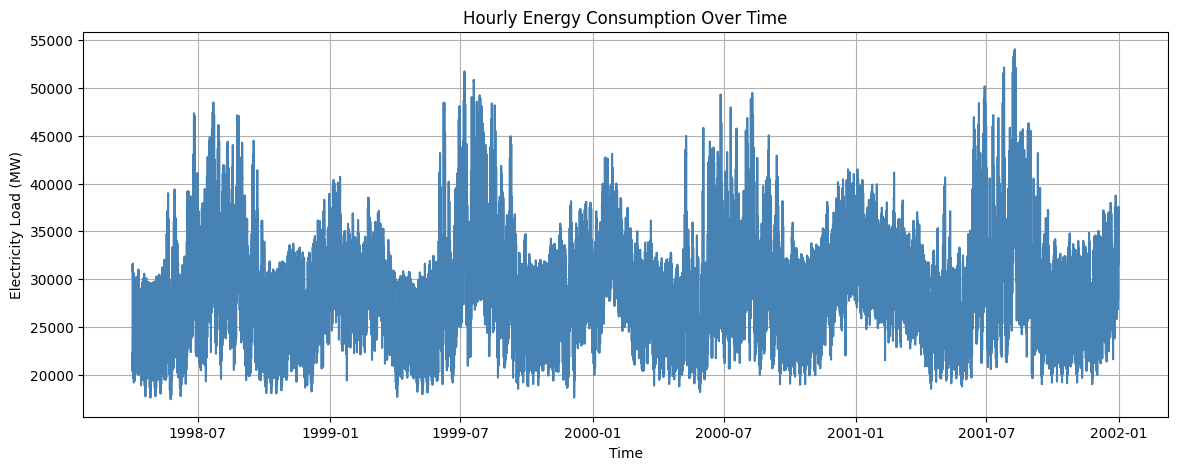

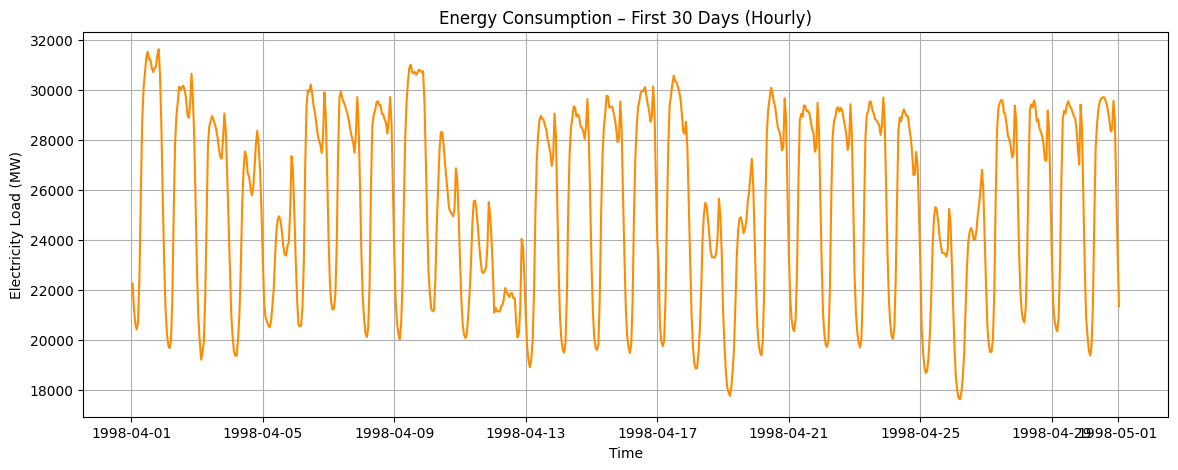

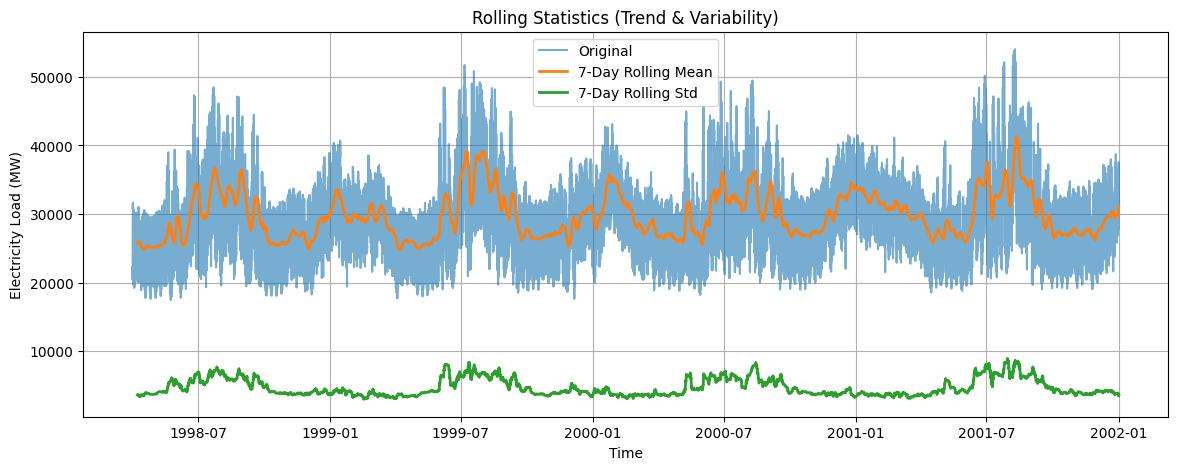

Augmented Dickey-Fuller Test Results:
ADF Statistic: -13.1721
p-value: 0.0000
Critical Values:
   1%: -3.4305
   5%: -2.8616
   10%: -2.5668

Conclusion: The time series is stationary (reject null hypothesis).


In [7]:
# Time Series Exploration

import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

# ---- Plot full time series ----
plt.figure(figsize=(14, 5))
plt.plot(df.index, df['load'], color='steelblue')
plt.title("Hourly Energy Consumption Over Time")
plt.xlabel("Time")
plt.ylabel("Electricity Load (MW)")
plt.grid(True)
plt.show()

# ---- Plot a smaller window to visualize seasonality (first 30 days) ----
plt.figure(figsize=(14, 5))
plt.plot(df.iloc[:24*30].index, df.iloc[:24*30]['load'], color='darkorange')
plt.title("Energy Consumption – First 30 Days (Hourly)")
plt.xlabel("Time")
plt.ylabel("Electricity Load (MW)")
plt.grid(True)
plt.show()

# ---- Rolling statistics to observe trend & variance ----
rolling_mean = df['load'].rolling(window=24*7).mean()   # 7-day rolling mean
rolling_std = df['load'].rolling(window=24*7).std()     # 7-day rolling std

plt.figure(figsize=(14, 5))
plt.plot(df['load'], label='Original', alpha=0.6)
plt.plot(rolling_mean, label='7-Day Rolling Mean', linewidth=2)
plt.plot(rolling_std, label='7-Day Rolling Std', linewidth=2)
plt.title("Rolling Statistics (Trend & Variability)")
plt.xlabel("Time")
plt.ylabel("Electricity Load (MW)")
plt.legend()
plt.grid(True)
plt.show()

# ---- Stationarity Test: Augmented Dickey-Fuller (ADF) ----
adf_result = adfuller(df['load'])

print("Augmented Dickey-Fuller Test Results:")
print(f"ADF Statistic: {adf_result[0]:.4f}")
print(f"p-value: {adf_result[1]:.4f}")
print("Critical Values:")
for key, value in adf_result[4].items():
    print(f"   {key}: {value:.4f}")

# Interpretation
if adf_result[1] < 0.05:
    print("\nConclusion: The time series is stationary (reject null hypothesis).")
else:
    print("\nConclusion: The time series is non-stationary (fail to reject null hypothesis).")


***Data Preprocessing***

In [8]:
def preprocess_timeseries(data):
    """
    Preprocess time series data
    
    Args:
        data: raw time series data
    
    Returns:
        preprocessed data, scaler
    """
    if isinstance(data, pd.Series):
        data = data.to_frame(name='load')

    # ---- Handle missing values (forward fill, then backward fill if needed) ----
    data = data.fillna(method='ffill')
    data = data.fillna(method='bfill')

    # ---- Normalize data (Standardization) ----
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(data.values)

    return scaled_data, scaler

In [9]:
def create_sequences(data, seq_length, pred_horizon):
    """
    Create sequences for time series prediction
    
    Args:
        data: preprocessed time series data
        seq_length: lookback window
        pred_horizon: forecast steps ahead
    
    Returns:
        X: input sequences, y: target values
    """
    X, y = [], []
    
    for i in range(len(data) - seq_length - pred_horizon + 1):
        X.append(data[i : i + seq_length])
        y.append(data[i + seq_length : i + seq_length + pred_horizon])
    
    X = np.array(X)
    y = np.array(y)
    
    return X, y

**Preprocess data and
Create sequences**

In [10]:
# Temporal train/test split (NO SHUFFLING)
raw_data = df[['load']]
train_test_ratio = "90/10"
split_idx = int(len(raw_data) * 0.9)

train_data = raw_data.iloc[:split_idx]
test_data = raw_data.iloc[split_idx:]

# ---- Preprocess (fit scaler ONLY on training data) ----
train_scaled, scaler = preprocess_timeseries(train_data)
test_scaled = scaler.transform(test_data.values)

# ---- Create sequences ----
X_train, y_train = create_sequences(
    train_scaled,
    seq_length=sequence_length,
    pred_horizon=prediction_horizon
)

X_test, y_test = create_sequences(
    test_scaled,
    seq_length=sequence_length,
    pred_horizon=prediction_horizon
)

train_samples = X_train.shape[0]  # Number of training sequences
test_samples = X_test.shape[0]  # Number of test sequences

/var/folders/sc/jmdk37m56gn0_p9z_522pm7r0000gn/T/ipykernel_954/1998102385.py:15: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data = data.fillna(method='ffill')
/var/folders/sc/jmdk37m56gn0_p9z_522pm7r0000gn/T/ipykernel_954/1998102385.py:16: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data = data.fillna(method='bfill')


In [11]:
print(f"\nTrain/Test Split: {train_test_ratio}")
print(f"Training Samples: {train_samples}")
print(f"Test Samples: {test_samples}")


Train/Test Split: 90/10
Training Samples: 29582
Test Samples: 3266


**LSTM Architecture Design**

In [12]:
def build_rnn_model(model_type, input_shape, hidden_units, n_layers, output_size):
    """
    Build LSTM model
    
    Args:
        model_type: string ('LSTM')
        input_shape: tuple (sequence_length, n_features)
        hidden_units: number of hidden units per layer
        n_layers: number of stacked layers (minimum 2)
        output_size: prediction horizon
    
    Returns:
        model: compiled RNN model
    """
    # Implement LSTM architecture
    # Stack at least 2 layers
    # Add output layer
    if n_layers < 2:
        raise ValueError("LSTM must have at least 2 stacked layers")
    
    model = Sequential()
    
    # First LSTM layer
    model.add(LSTM(hidden_units, return_sequences=True, input_shape=input_shape))
    
    # Second (stacked) LSTM layer
    model.add(LSTM(hidden_units))
    
    # Output layer
    model.add(Dense(output_size))
    
    model.compile(
        optimizer=Adam(),
        loss='mse',
        metrics=['mae']
    )
    
    return model


# Create LSTM model
rnn_model = build_rnn_model(
    model_type='LSTM',
    input_shape=(sequence_length, n_features),
    hidden_units=64,
    n_layers=2,
    output_size=prediction_horizon
)

rnn_model.summary()

2026-05-05 12:24:16.432513: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M5
2026-05-05 12:24:16.432701: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-05-05 12:24:16.432710: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-05-05 12:24:16.432911: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-05-05 12:24:16.432930: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)
/opt/anaconda3/envs/tf_env/lib/python3.10/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential 

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49,985 (195.25 KB)

 Trainable params: 49,985 (195.25 KB)

 Non-trainable params: 0 (0.00 B)

**Train RNN Model**

In [13]:
print("\n" + "="*70)
print("RNN MODEL TRAINING")
print("="*70)


RNN MODEL TRAINING


In [14]:
# Track training time
rnn_start_time = time.time()

Train your model

In [15]:
history = rnn_model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/50


2026-05-05 12:24:21.756325: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


832/832 ━━━━━━━━━━━━━━━━━━━━ 15s 17ms/step - loss: 0.0677 - mae: 0.1655 - val_loss: 0.0150 - val_mae: 0.0948
Epoch 2/50
832/832 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - loss: 0.0102 - mae: 0.0746 - val_loss: 0.0121 - val_mae: 0.0850
Epoch 3/50
832/832 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - loss: 0.0083 - mae: 0.0669 - val_loss: 0.0077 - val_mae: 0.0670
Epoch 4/50
832/832 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - loss: 0.0072 - mae: 0.0614 - val_loss: 0.0054 - val_mae: 0.0540
Epoch 5/50
832/832 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - loss: 0.0065 - mae: 0.0583 - val_loss: 0.0049 - val_mae: 0.0504
Epoch 6/50
832/832 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - loss: 0.0061 - mae: 0.0563 - val_loss: 0.0048 - val_mae: 0.0490
Epoch 7/50
832/832 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - loss: 0.0058 - mae: 0.0550 - val_loss: 0.0047 - val_mae: 0.0483
Epoch 8/50
832/832 ━━━━━━━━━━━━━━━━━━━━ 15s 19ms/step - loss: 0.0056 - mae: 0.0539 - val_loss: 0.0045 - val_mae: 0.0472
Epoch 9/50
832/832 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/st

In [16]:
rnn_training_time = time.time() - rnn_start_time

In [17]:
# Track initial and final loss
rnn_initial_loss = history.history['loss'][0]  # Get from training history (first epoch)
rnn_final_loss = history.history['loss'][-1]  # Get from training history (last epoch)

In [18]:
print(f"Training completed in {rnn_training_time:.2f} seconds")
print(f"Initial Loss: {rnn_initial_loss:.4f}")
print(f"Final Loss: {rnn_final_loss:.4f}")
print("="*70)

Training completed in 548.83 seconds
Initial Loss: 0.0677
Final Loss: 0.0026


**Evaluate RNN Model**

In [19]:
def calculate_mape(y_true, y_pred):
    """Calculate Mean Absolute Percentage Error"""
    
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    
    # Avoid division by zero
    epsilon = 1e-8
    return np.mean(np.abs((y_true - y_pred) / (y_true + epsilon))) * 100

In [20]:
# Calculate all 4 metrics
# ---- Make predictions on test set ----
y_pred_scaled = rnn_model.predict(X_test)

# ---- Reshape for inverse scaling ----
y_test_reshaped = y_test.reshape(-1, 1)
y_pred_reshaped = y_pred_scaled.reshape(-1, 1)

# ---- Inverse transform (IMPORTANT) ----
y_test_inv = scaler.inverse_transform(y_test_reshaped)
y_pred_inv = scaler.inverse_transform(y_pred_reshaped)

# ---- Calculate metrics ----
rnn_mae = mean_absolute_error(y_test_inv, y_pred_inv)  # mean_absolute_error(y_test, y_pred)
rnn_rmse = np.sqrt(mean_squared_error(y_test_inv, y_pred_inv))  # sqrt(mean_squared_error(y_test, y_pred))
rnn_mape = calculate_mape(y_test_inv, y_pred_inv)  # calculate_mape(y_test, y_pred)
rnn_r2 = r2_score(y_test_inv, y_pred_inv)  # r2_score(y_test, y_pred)

103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


In [21]:
print("\nRNN Model Performance:")
print(f"MAE:   {rnn_mae:.4f}")
print(f"RMSE:  {rnn_rmse:.4f}")
print(f"MAPE:  {rnn_mape:.4f}%")
print(f"R² Score: {rnn_r2:.4f}")


RNN Model Performance:
MAE:   223.1334
RMSE:  302.2217
MAPE:  0.7724%
R² Score: 0.9966


Visualize RNN Results

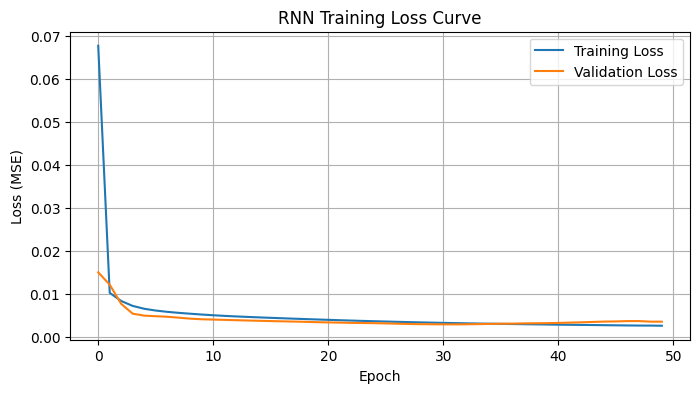

In [22]:
# ---- 1. Plot training loss curve ----
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='Training Loss')
if 'val_loss' in history.history:
    plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("RNN Training Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.grid(True)
plt.show()

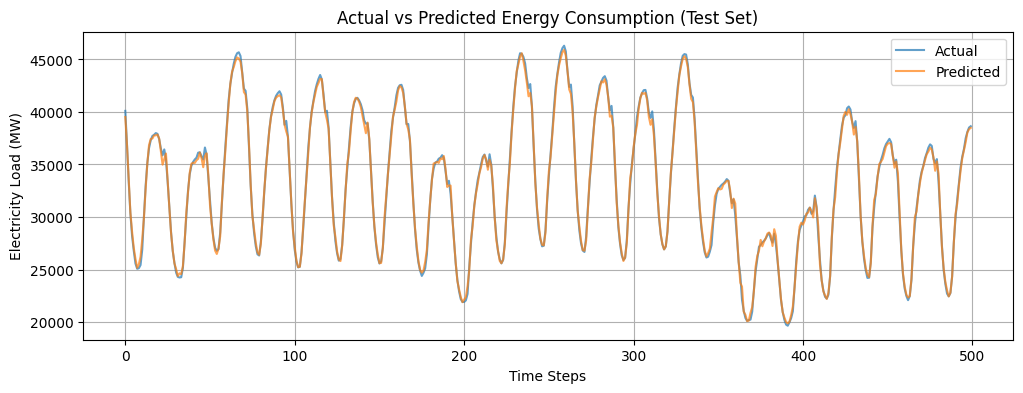

In [23]:
# ---- 2. Plot actual vs predicted values (subset for clarity) ----
num_points = 500  # plot a subset to keep visualization clean

plt.figure(figsize=(12, 4))
plt.plot(y_test_inv[:num_points], label='Actual', alpha=0.7)
plt.plot(y_pred_inv[:num_points], label='Predicted', alpha=0.7)
plt.title("Actual vs Predicted Energy Consumption (Test Set)")
plt.xlabel("Time Steps")
plt.ylabel("Electricity Load (MW)")
plt.legend()
plt.grid(True)
plt.show()

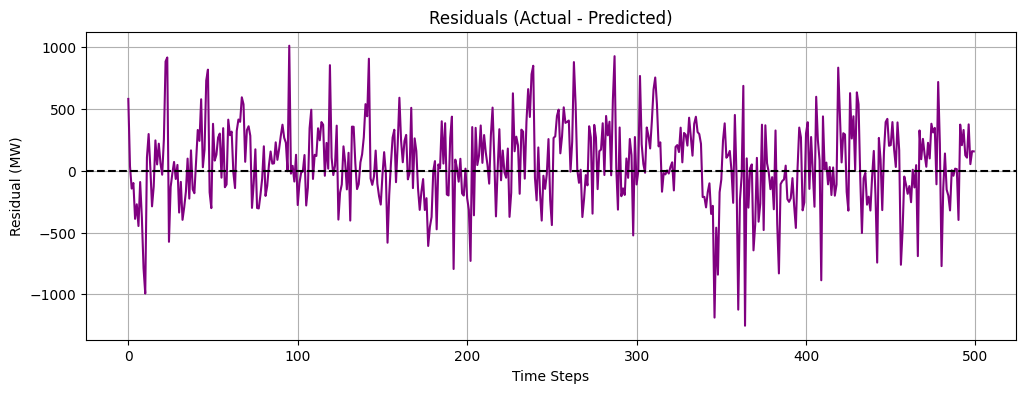

In [24]:
# ---- 3. Plot residuals ----
residuals = y_test_inv - y_pred_inv

plt.figure(figsize=(12, 4))
plt.plot(residuals[:num_points], color='purple')
plt.axhline(0, linestyle='--', color='black')
plt.title("Residuals (Actual - Predicted)")
plt.xlabel("Time Steps")
plt.ylabel("Residual (MW)")
plt.grid(True)
plt.show()

**Positional Encoding Implementation**

In [25]:
def positional_encoding(seq_length, d_model):

    position = np.arange(seq_length)[:, np.newaxis]          # (seq_length, 1)
    div_term = np.exp(
        np.arange(0, d_model, 2) * (-np.log(10000.0) / d_model)
    )                                                         # (d_model/2,)

    pe = np.zeros((seq_length, d_model))
    pe[:, 0::2] = np.sin(position * div_term)
    pe[:, 1::2] = np.cos(position * div_term)

    return pe

**Transformer Encoder Architecture**

In [26]:
from tensorflow.keras import layers

def build_transformer_model(seq_length, n_features, d_model, n_heads, n_layers, d_ff, output_size):
    inputs = layers.Input(shape=(seq_length, n_features))
    
    # Project to d_model
    x = layers.Dense(d_model)(inputs)
    
    # Add positional encoding
    x = x + positional_encoding(seq_length, d_model)
    
    # Stack transformer encoder layers
    for _ in range(n_layers):
        # Multi-head attention
        attn_output = layers.MultiHeadAttention(
            num_heads=n_heads, 
            key_dim=d_model // n_heads
        )(x, x)
        x = layers.LayerNormalization()(x + attn_output)
        
        # Feed-forward
        ffn_output = layers.Dense(d_ff, activation='relu')(x)
        ffn_output = layers.Dense(d_model)(ffn_output)
        x = layers.LayerNormalization()(x + ffn_output)
    
    # Output
    x = layers.GlobalAveragePooling1D()(x)
    outputs = layers.Dense(output_size)(x)
    
    model = models.Model(inputs=inputs, outputs=outputs)

    # ---- Compile model ----
    model.compile(
        optimizer='adam',
        loss='mse',
        metrics=['mae']
    )

    return model

**Build Transformer Model**

In [27]:
# Build Transformer Model

# Create Transformer model
transformer_model = build_transformer_model(
    seq_length=sequence_length,
    n_features=n_features,
    d_model=64,
    n_heads=4,
    n_layers=2,
    d_ff=256,
    output_size=prediction_horizon
)

# Display model summary
transformer_model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 24, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 24, 64)    │        128 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 24, 64)    │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 24, 64)    │     16,640 │ add[0][0],        │
│ (MultiHeadAttentio… │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 24, 64)    │          0 │ add[0][0],        │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 24, 64)    │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 24, 256)   │     16,640 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 24, 64)    │     16,448 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 24, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 24, 64)    │        128 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 24, 64)    │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 24, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 24, 64)    │        128 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 24, 256)   │     16,640 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 24, 64)    │     16,448 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 24, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 24, 64)    │        128 │ add_4[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 1)         │         65 │ global_average_p

 Total params: 100,161 (391.25 KB)

 Trainable params: 100,161 (391.25 KB)

 Non-trainable params: 0 (0.00 B)

**Train Transformer Model**

In [28]:
print("\n" + "="*70)
print("TRANSFORMER MODEL TRAINING")
print("="*70)


TRANSFORMER MODEL TRAINING


In [29]:
# Track training time
transformer_start_time = time.time()

In [30]:
history_transformer = transformer_model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)

Epoch 1/50
925/925 ━━━━━━━━━━━━━━━━━━━━ 32s 33ms/step - loss: 0.0563 - mae: 0.1416 - val_loss: 0.0163 - val_mae: 0.1056
Epoch 2/50
925/925 ━━━━━━━━━━━━━━━━━━━━ 31s 34ms/step - loss: 0.0115 - mae: 0.0817 - val_loss: 0.0097 - val_mae: 0.0788
Epoch 3/50
925/925 ━━━━━━━━━━━━━━━━━━━━ 32s 34ms/step - loss: 0.0099 - mae: 0.0759 - val_loss: 0.0081 - val_mae: 0.0684
Epoch 4/50
925/925 ━━━━━━━━━━━━━━━━━━━━ 32s 35ms/step - loss: 0.0093 - mae: 0.0730 - val_loss: 0.0068 - val_mae: 0.0609
Epoch 5/50
925/925 ━━━━━━━━━━━━━━━━━━━━ 31s 34ms/step - loss: 0.0094 - mae: 0.0733 - val_loss: 0.0099 - val_mae: 0.0763
Epoch 6/50
925/925 ━━━━━━━━━━━━━━━━━━━━ 32s 34ms/step - loss: 0.0095 - mae: 0.0742 - val_loss: 0.0130 - val_mae: 0.0883
Epoch 7/50
925/925 ━━━━━━━━━━━━━━━━━━━━ 32s 34ms/step - loss: 0.0106 - mae: 0.0788 - val_loss: 0.0128 - val_mae: 0.0876
Epoch 8/50
925/925 ━━━━━━━━━━━━━━━━━━━━ 32s 35ms/step - loss: 0.0122 - mae: 0.0841 - val_loss: 0.0133 - val_mae: 0.0922
Epoch 9/50
925/925 ━━━━━━━━━━━━━━━━━━━━ 

In [31]:
transformer_training_time = time.time() - transformer_start_time

In [32]:
# Track initial and final loss
transformer_initial_loss = history_transformer.history['loss'][0]  # Get from training history (first epoch)
transformer_final_loss = history_transformer.history['loss'][-1]  # Get from training history (last epoch)

In [33]:
print(f"Training completed in {transformer_training_time:.2f} seconds")
print(f"Initial Loss: {transformer_initial_loss:.4f}")
print(f"Final Loss: {transformer_final_loss:.4f}")
print("="*70)

Training completed in 1589.66 seconds
Initial Loss: 0.0563
Final Loss: 0.0462


**Evaluate Transformer Model**

In [34]:
# Calculate all 4 metrics
# ---- Make predictions on test set ----
y_pred_trans_scaled = transformer_model.predict(X_test)

# ---- Reshape for inverse scaling ----
y_test_reshaped = y_test.reshape(-1, 1)
y_pred_trans_reshaped = y_pred_trans_scaled.reshape(-1, 1)

# ---- Inverse transform ----
y_test_inv = scaler.inverse_transform(y_test_reshaped)
y_pred_trans_inv = scaler.inverse_transform(y_pred_trans_reshaped)

transformer_mae = mean_absolute_error(y_test_inv, y_pred_trans_inv)  # mean_absolute_error(y_test, y_pred)
transformer_rmse = np.sqrt(mean_squared_error(y_test_inv, y_pred_trans_inv))  # sqrt(mean_squared_error(y_test, y_pred))
transformer_mape = calculate_mape(y_test_inv, y_pred_trans_inv)  # calculate_mape(y_test, y_pred)
transformer_r2 = r2_score(y_test_inv, y_pred_trans_inv)  # r2_score(y_test, y_pred)

103/103 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step


In [35]:
print("\nTransformer Model Performance:")
print(f"MAE:   {transformer_mae:.4f}")
print(f"RMSE:  {transformer_rmse:.4f}")
print(f"MAPE:  {transformer_mape:.4f}%")
print(f"R² Score: {transformer_r2:.4f}")


Transformer Model Performance:
MAE:   740.3031
RMSE:  1014.7166
MAPE:  2.6238%
R² Score: 0.9612


**Visualize Transformer Results**

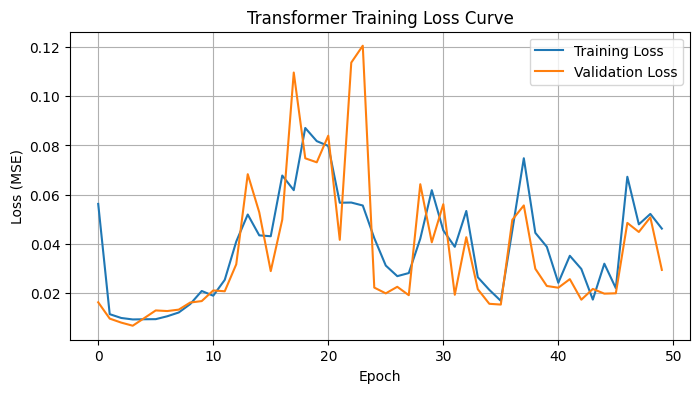

In [36]:
# ---- 1. Plot training loss curve ----
plt.figure(figsize=(8, 4))
plt.plot(history_transformer.history['loss'], label='Training Loss')
if 'val_loss' in history_transformer.history:
    plt.plot(history_transformer.history['val_loss'], label='Validation Loss')
plt.title("Transformer Training Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.grid(True)
plt.show()

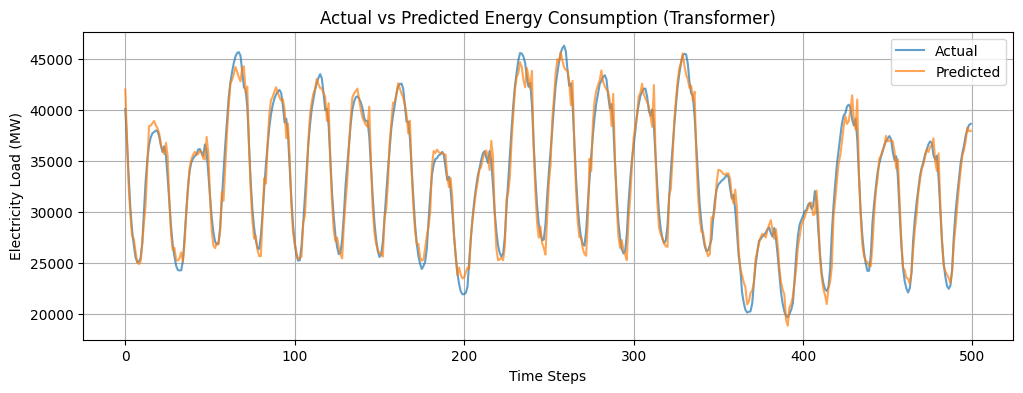

In [37]:
# ---- 2. Plot actual vs predicted values (subset for clarity) ----
num_points = 500

plt.figure(figsize=(12, 4))
plt.plot(y_test_inv[:num_points], label='Actual', alpha=0.7)
plt.plot(y_pred_trans_inv[:num_points], label='Predicted', alpha=0.7)
plt.title("Actual vs Predicted Energy Consumption (Transformer)")
plt.xlabel("Time Steps")
plt.ylabel("Electricity Load (MW)")
plt.legend()
plt.grid(True)
plt.show()

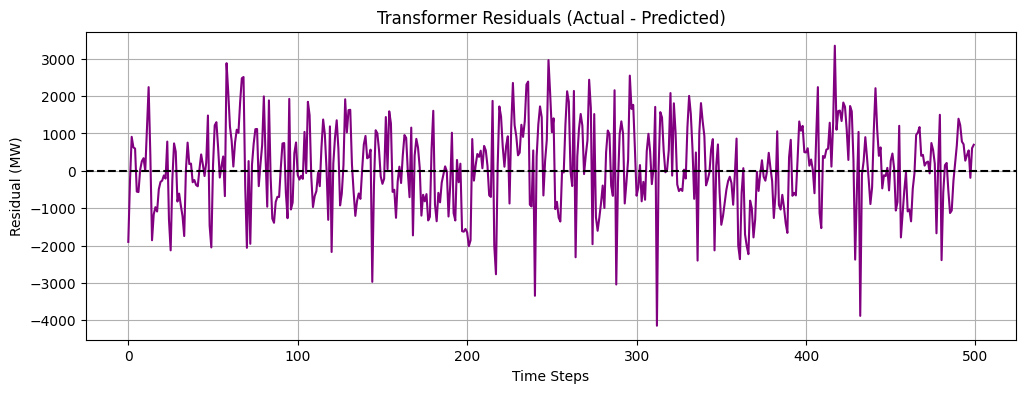

In [38]:
# ---- 3. Plot residuals ----
residuals = y_test_inv - y_pred_trans_inv

plt.figure(figsize=(12, 4))
plt.plot(residuals[:num_points], color='purple')
plt.axhline(0, linestyle='--', color='black')
plt.title("Transformer Residuals (Actual - Predicted)")
plt.xlabel("Time Steps")
plt.ylabel("Residual (MW)")
plt.grid(True)
plt.show()

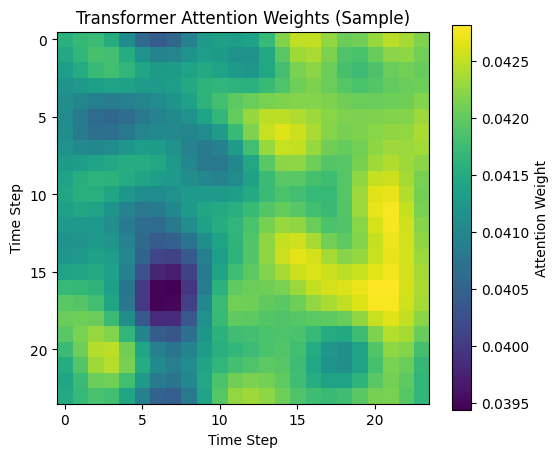

In [39]:
# Take a single test sample
sample_input = X_test[:1]  # shape: (1, seq_length, n_features)

# Project input to d_model (same as model)
projection_layer = transformer_model.layers[1]  # Dense projection
projected = projection_layer(sample_input)

# Add positional encoding
pos_encoding = positional_encoding(sequence_length, projected.shape[-1])
projected += tf.cast(pos_encoding, tf.float32)

# Recreate ONE attention layer for visualization
attention_layer = tf.keras.layers.MultiHeadAttention(
    num_heads=4,
    key_dim=64 // 4
)

# Get attention scores
_, attention_scores = attention_layer(
    projected,
    projected,
    return_attention_scores=True
)

# Average across heads
attention_scores = tf.reduce_mean(attention_scores, axis=1).numpy()

# Plot attention heatmap
plt.figure(figsize=(6, 5))
plt.imshow(attention_scores[0], cmap='viridis')
plt.colorbar(label='Attention Weight')
plt.title("Transformer Attention Weights (Sample)")
plt.xlabel("Time Step")
plt.ylabel("Time Step")
plt.show()

**Metrics Comparison**

In [40]:
print("\n" + "="*70)
print("MODEL COMPARISON")
print("="*70)


MODEL COMPARISON


In [41]:
# Get total trainable parameters
rnn_total_params = rnn_model.count_params()
transformer_total_params = transformer_model.count_params()

In [42]:
comparison_df = pd.DataFrame({
    'Metric': ['MAE', 'RMSE', 'MAPE (%)', 'R² Score', 'Training Time (s)', 'Parameters'],
    'RNN (LSTM/GRU)': [
        rnn_mae,
        rnn_rmse,
        rnn_mape,
        rnn_r2,
        rnn_training_time,
        rnn_total_params  
    ],
    'Transformer': [
        transformer_mae,
        transformer_rmse,
        transformer_mape,
        transformer_r2,
        transformer_training_time,
        transformer_total_params  
    ]
})

In [43]:
print(comparison_df.to_string(index=False))
print("="*70)

           Metric  RNN (LSTM/GRU)   Transformer
              MAE      223.133351    740.303071
             RMSE      302.221700   1014.716615
         MAPE (%)        0.772395      2.623829
         R² Score        0.996557      0.961182
Training Time (s)      548.830851   1589.662242
       Parameters    49985.000000 100161.000000


**Visual Comparison**

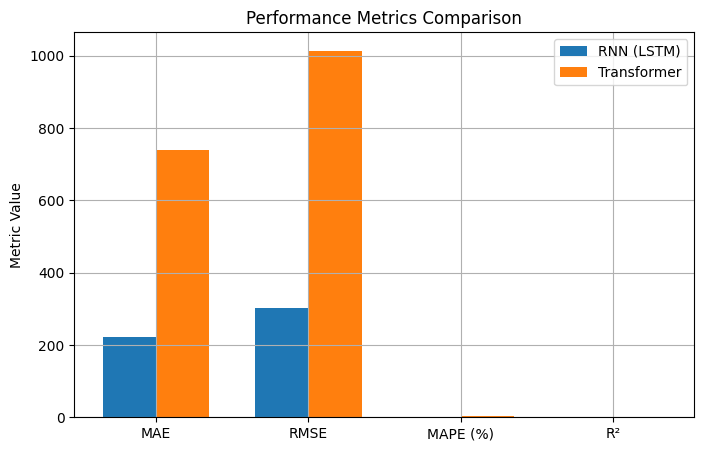

In [44]:
# ---------- 1. Bar plot: Metrics comparison ----------
metrics = ['MAE', 'RMSE', 'MAPE (%)', 'R²']
rnn_values = [rnn_mae, rnn_rmse, rnn_mape, rnn_r2]
transformer_values = [transformer_mae, transformer_rmse, transformer_mape, transformer_r2]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - width/2, rnn_values, width, label='RNN (LSTM)')
plt.bar(x + width/2, transformer_values, width, label='Transformer')

plt.xticks(x, metrics)
plt.ylabel('Metric Value')
plt.title('Performance Metrics Comparison')
plt.legend()
plt.grid(True)
plt.show()

In [45]:
# Flatten predictions for plotting
y_test_plot = y_test_inv.squeeze()
y_pred_rnn_plot = y_pred_inv.squeeze()
y_pred_transformer_plot = y_pred_trans_inv.squeeze()

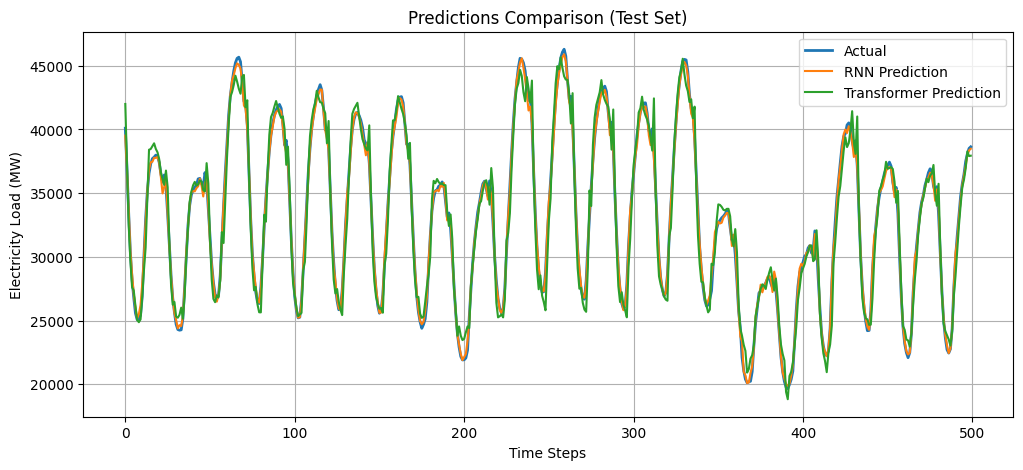

In [46]:
# ---------- 2. Predictions comparison (Actual vs RNN vs Transformer) ----------
plt.figure(figsize=(12, 5))
plt.plot(y_test_plot[:500], label='Actual', linewidth=2)
plt.plot(y_pred_rnn_plot[:500], label='RNN Prediction')
plt.plot(y_pred_transformer_plot[:500], label='Transformer Prediction')

plt.title('Predictions Comparison (Test Set)')
plt.xlabel('Time Steps')
plt.ylabel('Electricity Load (MW)')
plt.legend()
plt.grid(True)
plt.show()

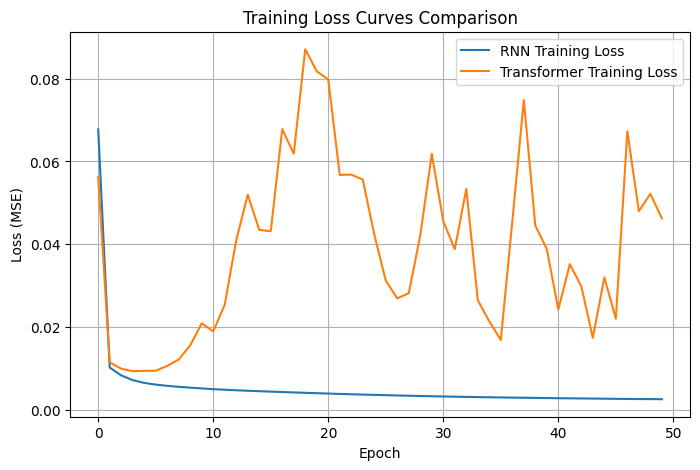

In [47]:
# ---------- 3. Training loss curves comparison ----------
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='RNN Training Loss')
plt.plot(history_transformer.history['loss'], label='Transformer Training Loss')

plt.title('Training Loss Curves Comparison')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True)
plt.show()